# Goodreads Rating Prediction
Advanced Databases (CIS 604) project: predicting a book's average rating with SQL/DuckDB and XGBoost.

Salam Khalid Aldoyofy

***The goal of this project is to predict the average rating of a book on Goodreads (regression) using metadata such as page count,genres,publication year,language, and author popularity***

## 1. Setup and data loading

Setup: the dataset (pfaha/goodreads-books on Hugging Face) was downloaded once and saved as a Parquet snapshot on Google Drive. Every session loads it from there.

In [1]:
!pip install -q xgboost duckdb

import pandas as pd
import duckdb
from google.colab import drive

drive.mount('/content/drive')

df = pd.read_parquet('/content/drive/MyDrive/goodreads_snapshot.parquet')
con = duckdb.connect('/content/drive/MyDrive/goodreads.duckdb')

Mounted at /content/drive


In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 315000 entries, 0 to 314999
Data columns (total 24 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   title                        315000 non-null  object 
 1   contributors                 315000 non-null  object 
 2   first_author                 314850 non-null  object 
 3   description                  273602 non-null  object 
 4   genres                       315000 non-null  object 
 5   series                       315000 non-null  object 
 6   format                       311719 non-null  object 
 7   pages                        290355 non-null  float64
 8   language                     302556 non-null  object 
 9   asin                         313074 non-null  object 
 10  isbn10                       296706 non-null  object 
 11  isbn13                       295830 non-null  object 
 12  publisher                    309971 non-null  object 
 13 

***The dataset contains 315,000 book records with 24 attributes, including numerical, categorical, textual, and nested (list-type) fields.***

In [3]:
df.shape

(315000, 24)

## 2. Target variable

***The task is formulated as a regression problem: predicting a book's average_rating from its metadata. Performance is evaluated using MSE, RMSE, MAE and R².***

In [4]:
print(df['average_rating'].describe())
print((df['average_rating']==0).sum(),"books with rating 0")
print(df['catalog_guideline_violation'].value_counts())
print(df['book_id'].duplicated().sum(),"duplicate book_id")

for t in [1,10,50,100]:
    print(f"ratings_count >= {t}: {(df['ratings_count'] >= t).sum()}")

count    314747.000000
mean          2.696081
std           1.826884
min           0.000000
25%           0.000000
50%           3.610000
75%           4.000000
max           5.000000
Name: average_rating, dtype: float64
93352 books with rating 0
catalog_guideline_violation
False    315000
Name: count, dtype: int64
0 duplicate book_id
ratings_count >= 1: 221395
ratings_count >= 10: 125570
ratings_count >= 50: 80677
ratings_count >= 100: 66088


*Around 30% of records (93,352) have an average rating of 0. These books have no user ratings, so a value of 0 represents missing information rather than a genuine rating. The catalog_guideline_violation column contained no violations and no duplicate book_id values were found.*

In [5]:
print(((df['average_rating'] == 0) & (df['ratings_count'] == 0)).sum())
print(df['average_rating'].isna().sum())

93352
253


*Books with fewer than 10 ratings were removed because their averages are statistically unreliable. This yielded 125,570 books. The constant column catalog_guideline_violation was dropped.*

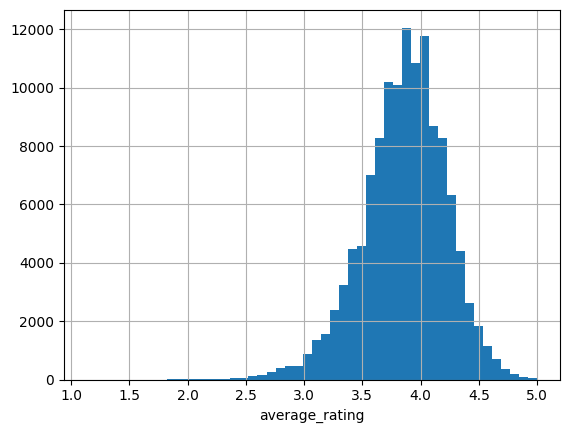

In [6]:
import matplotlib.pyplot as plt
df[df['ratings_count'] >= 10]['average_rating'].hist(bins=50)
plt.xlabel('average_rating')
plt.show()

## 3. DuckDB database and SQL cleaning

In [7]:
import duckdb
con = duckdb.connect('/content/drive/MyDrive/goodreads.duckdb')

con.execute("""
CREATE OR REPLACE TABLE books AS
SELECT * FROM read_parquet('/content/drive/MyDrive/goodreads_snapshot.parquet')
""")

print(con.execute("SELECT COUNT(*) FROM books").fetchone())

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

(315000,)


***The data was loaded into a DuckDB database file (table books) and validated with SQL queries that reproduced the counts obtained in pandas.***

In [8]:
con.execute(""" SELECT COUNT(*) AS n_books,
                       SUM (CASE WHEN ratings_count >= 10 THEN 1 ELSE 0 END) AS n_ge10,
                       ROUND(AVG(CASE WHEN ratings_count >= 10 THEN average_rating END), 3) AS avg_rating_ge10
                FROM books""").df()

,n_books,n_ge10,avg_rating_ge10
0,315000,125570.0,3.857


**After filtering, missing values were profiled with SQL to decide the imputation strategy for each feature.**

***here we filtered the missing values :***

In [9]:
con.execute("""
SELECT COUNT(*) AS n,
       SUM(CASE WHEN pages IS NULL THEN 1 ELSE 0 END) AS pages_null, SUM(CASE WHEN language IS NULL THEN 1 ELSE 0 END) AS language_null,
       SUM(CASE WHEN format IS NULL THEN 1 ELSE 0 END) AS format_null,
       SUM(CASE WHEN publisher IS NULL THEN 1 ELSE 0 END) AS publisher_null,
       SUM(CASE WHEN publication_date IS NULL THEN 1 ELSE 0 END) AS date_null,
       SUM(CASE WHEN description IS NULL THEN 1 ELSE 0 END) AS desc_null
FROM books
WHERE ratings_count >= 10""").df()

,n,pages_null,language_null,format_null,publisher_null,date_null,desc_null
0,125570,9817.0,4975.0,1652.0,3097.0,6995.0,1742.0


***here we placed the average of the rating, depending on the language:***

In [10]:
con.execute("""
SELECT language, COUNT(*) AS n_books, ROUND(AVG(average_rating), 3) AS avg_rating
FROM books
WHERE ratings_count >= 10 AND language IS NOT NULL
GROUP BY language
HAVING COUNT(*) >= 500
ORDER BY n_books DESC
""").df()

,language,n_books,avg_rating
0,English,99556,3.863
1,Spanish; Castilian,4569,3.853
2,German,4353,3.825
3,French,3914,3.824
4,Italian,1177,3.792
5,Indonesian,925,3.857
6,Japanese,804,3.958
7,Portuguese,711,3.878
8,Dutch; Flemish,705,3.706
9,Arabic,639,3.702


***here we placed whether the books in the series is as same as rating or not:***

In [11]:
con.execute("""
SELECT is_part_of_series, COUNT(*) AS n_books, ROUND(AVG(average_rating), 3) AS avg_rating
FROM books
WHERE ratings_count >= 10
GROUP BY is_part_of_series
""").df()

,is_part_of_series,n_books,avg_rating
0,False,92649,3.840
1,True,32921,3.906


**Grouped aggregations show whether categorical attributes (language, series membership) are associated with differences in average rating, which motivates including them as features.**

*Range checks on pages and publication year were used to detect implausible values before modeling.*

In [12]:
con.execute("""
SELECT MIN(pages) AS min_pages,
       quantile_cont(pages, 0.5) AS median_pages,
       MAX(pages) AS max_pages,
       SUM(CASE WHEN pages = 0 THEN 1 ELSE 0 END) AS zero_pages,
       SUM(CASE WHEN pages > 3000 THEN 1 ELSE 0 END) AS over_3000,
       MIN(YEAR(TRY_CAST(publication_date AS DATE))) AS min_year,
       MAX(YEAR(TRY_CAST(publication_date AS DATE))) AS max_year
FROM books
WHERE ratings_count >= 10
""").df()

,min_pages,median_pages,max_pages,zero_pages,over_3000,min_year,max_year
0,0,240.0,640128416,9513.0,51.0,87,9999


*The genres column is a list; it was unnested with SQL to analyze genre frequency and its relation to rating.*

In [13]:
con.execute("""
SELECT genre, COUNT(*) AS n_books, ROUND(AVG(average_rating), 3) AS avg_rating
FROM (SELECT UNNEST(genres) AS genre, average_rating
      FROM books WHERE ratings_count >= 10)
GROUP BY genre
ORDER BY n_books DESC
LIMIT 15
""").df()

,genre,n_books,avg_rating
0,Fiction,45122,3.842
1,Nonfiction,34019,3.922
2,Classics,17406,3.920
3,History,16136,3.922
4,Audiobook,15174,3.913
5,Fantasy,13389,3.902
6,Romance,13170,3.811
7,Historical Fiction,12416,3.877
8,Childrens,12328,3.924
9,Mystery,11966,3.824


***A cleaned table books_clean was created in DuckDB by applying the filtering rules in SQL. Genres were normalized into a separate table book_genres (one row per book–genre pair), following a one-to-many relational design. Author popularity features (author_followers, author_works) were extracted from the nested contributors field.***

In [14]:
con.execute("""
CREATE OR REPLACE TABLE books_clean AS
SELECT book_id, title, first_author, description, format, pages, language,
       publisher, publication_date, average_rating, ratings_count, reviews_count,
       num_editions, is_part_of_series,
       struct_extract(contributors[1], 'num_followers') AS author_followers,
       struct_extract(contributors[1], 'num_distinct_works') AS author_works,
       genres
FROM books
WHERE ratings_count >= 10
  AND average_rating IS NOT NULL
  AND average_rating > 0
""")

con.execute("""
CREATE OR REPLACE TABLE book_genres AS
SELECT book_id, UNNEST(genres) AS genre
FROM books_clean
""")

print(con.execute("SELECT COUNT(*) FROM books_clean").fetchone())
print(con.execute("SELECT COUNT(*) FROM book_genres").fetchone())

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

(125570,)
(661572,)


**Full missing values profile of the cleaned table was computed in SQL for every candidate feature**

In [15]:
con.execute("""
SELECT COUNT(*) AS n,
  SUM(CASE WHEN pages IS NULL THEN 1 ELSE 0 END) AS pages_null,
  SUM(CASE WHEN pages = 0 THEN 1 ELSE 0 END) AS pages_zero,
  SUM(CASE WHEN publication_date IS NULL THEN 1 ELSE 0 END) AS date_null,
  SUM(CASE WHEN description IS NULL THEN 1 ELSE 0 END) AS desc_null,
  SUM(CASE WHEN language IS NULL THEN 1 ELSE 0 END) AS language_null,
  SUM(CASE WHEN format IS NULL THEN 1 ELSE 0 END) AS format_null,
  SUM(CASE WHEN publisher IS NULL THEN 1 ELSE 0 END) AS publisher_null,
  SUM(CASE WHEN author_followers IS NULL THEN 1 ELSE 0 END) AS followers_null,
  SUM(CASE WHEN num_editions IS NULL THEN 1 ELSE 0 END) AS editions_null
FROM books_clean
""").df().T

,0
n,125570.0
pages_null,9817.0
pages_zero,9513.0
date_null,6995.0
desc_null,1742.0
language_null,4975.0
format_null,1652.0
publisher_null,3097.0
followers_null,12388.0
editions_null,1.0


**Check the range of the weird values**

In [16]:
con.execute("""
SELECT
  SUM(CASE WHEN pages BETWEEN 1 AND 9 THEN 1 ELSE 0 END) AS p_1_9,
  SUM(CASE WHEN pages BETWEEN 10 AND 49 THEN 1 ELSE 0 END) AS p_10_49,
  SUM(CASE WHEN pages BETWEEN 50 AND 999 THEN 1 ELSE 0 END) AS p_50_999,
  SUM(CASE WHEN pages BETWEEN 1000 AND 3000 THEN 1 ELSE 0 END) AS p_1000_3000,
  SUM(CASE WHEN pages > 3000 THEN 1 ELSE 0 END) AS p_over_3000
FROM books_clean
""").df().T

,0
p_1_9,1299.0
p_10_49,7365.0
p_50_999,96357.0
p_1000_3000,1168.0
p_over_3000,51.0


**The range profile showed implausible page counts(such as values above 3000 & 0) and publication years outside the historical range.**

In [17]:
con.execute("""
SELECT
  SUM(CASE WHEN y < 1450 THEN 1 ELSE 0 END) AS before_1450,
  SUM(CASE WHEN y BETWEEN 1450 AND 1899 THEN 1 ELSE 0 END) AS y_1450_1899,
  SUM(CASE WHEN y BETWEEN 1900 AND 2026 THEN 1 ELSE 0 END) AS y_1900_2026,
  SUM(CASE WHEN y > 2026 THEN 1 ELSE 0 END) AS after_2026
FROM (SELECT YEAR(TRY_CAST(publication_date AS DATE)) AS y FROM books_clean)
""").df().T

,0
before_1450,43.0
y_1450_1899,254.0
y_1900_2026,118251.0
after_2026,27.0


Implausible values were converted to NULL  rather than dropping records, and missing categorical values were encoded as "Unknown".
The result was stored in a new table books_prepared, preserving books_clean unchanged.

In [18]:
con.execute("""
CREATE OR REPLACE TABLE books_prepared AS
SELECT
  book_id, title, first_author, description,
  COALESCE(format, 'Unknown')    AS format,
  COALESCE(language, 'Unknown')  AS language,
  COALESCE(publisher, 'Unknown') AS publisher,
  CASE WHEN pages BETWEEN 10 AND 3000 THEN pages END AS pages,
  CASE WHEN YEAR(TRY_CAST(publication_date AS DATE)) BETWEEN 1450 AND 2026
       THEN YEAR(TRY_CAST(publication_date AS DATE)) END AS pub_year,
  num_editions, is_part_of_series, author_followers, author_works,
  genres, ratings_count, reviews_count, average_rating
FROM books_clean
""")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

**After cleaning validation confirmed that all remaining values fall inside the accepted ranges and that no records were lost**

In [19]:
con.execute("""
SELECT COUNT(*) AS n,
  MIN(pages) AS min_pages, quantile_cont(pages, 0.5) AS median_pages, MAX(pages) AS max_pages,
  MIN(pub_year) AS min_year, MAX(pub_year) AS max_year,
  SUM(CASE WHEN pages IS NULL THEN 1 ELSE 0 END) AS pages_null,
  SUM(CASE WHEN pub_year IS NULL THEN 1 ELSE 0 END) AS year_null,
  SUM(CASE WHEN language = 'Unknown' THEN 1 ELSE 0 END) AS lang_unknown
FROM books_prepared
""").df().T

,0
n,125570.0
min_pages,10.0
median_pages,256.0
max_pages,3000.0
min_year,1600.0
max_year,2026.0
pages_null,20680.0
year_null,7065.0
lang_unknown,4975.0


***Imputation is deferred until after the train/test split, and statistics are computed on the training set only, to prevent data leakage. XGBoost handles missing values natively; the linear baseline uses median imputation.***

In [20]:
con.execute("CHECKPOINT")

## 4. Exploratory data analysis

***The target variable is approximately bell-shaped with a left tail (skewness = -0.465), concentrated around 3.8–4.0, which makes regression with MSE-based metrics appropriate.***

(125570, 17)
count    125570.000000
mean          3.857305
std           0.359812
min           1.130000
25%           3.640000
50%           3.880000
75%           4.100000
max           5.000000
Name: average_rating, dtype: float64
skewness: -0.465


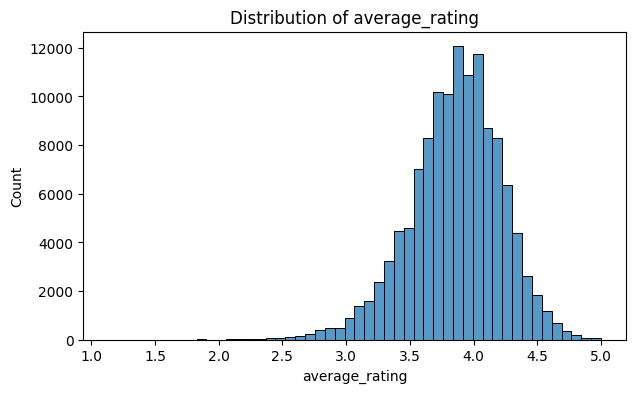

In [21]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

dfp = con.execute("SELECT * FROM books_prepared").df()
dfp ['is_part_of_series'] = dfp['is_part_of_series'].astype(int)
print(dfp.shape)

print(dfp['average_rating'].describe())
print("skewness:", round(dfp['average_rating'].skew(),3))

plt.figure(figsize=(7,4))
sns.histplot(dfp['average_rating'], bins=50)
plt.title('Distribution of average_rating')
plt.show()

***Count-type features (editions, followers, ratings, reviews) are highly right-skewed, so a log transform was used for visualization and will be considered for linear models.***

numpy


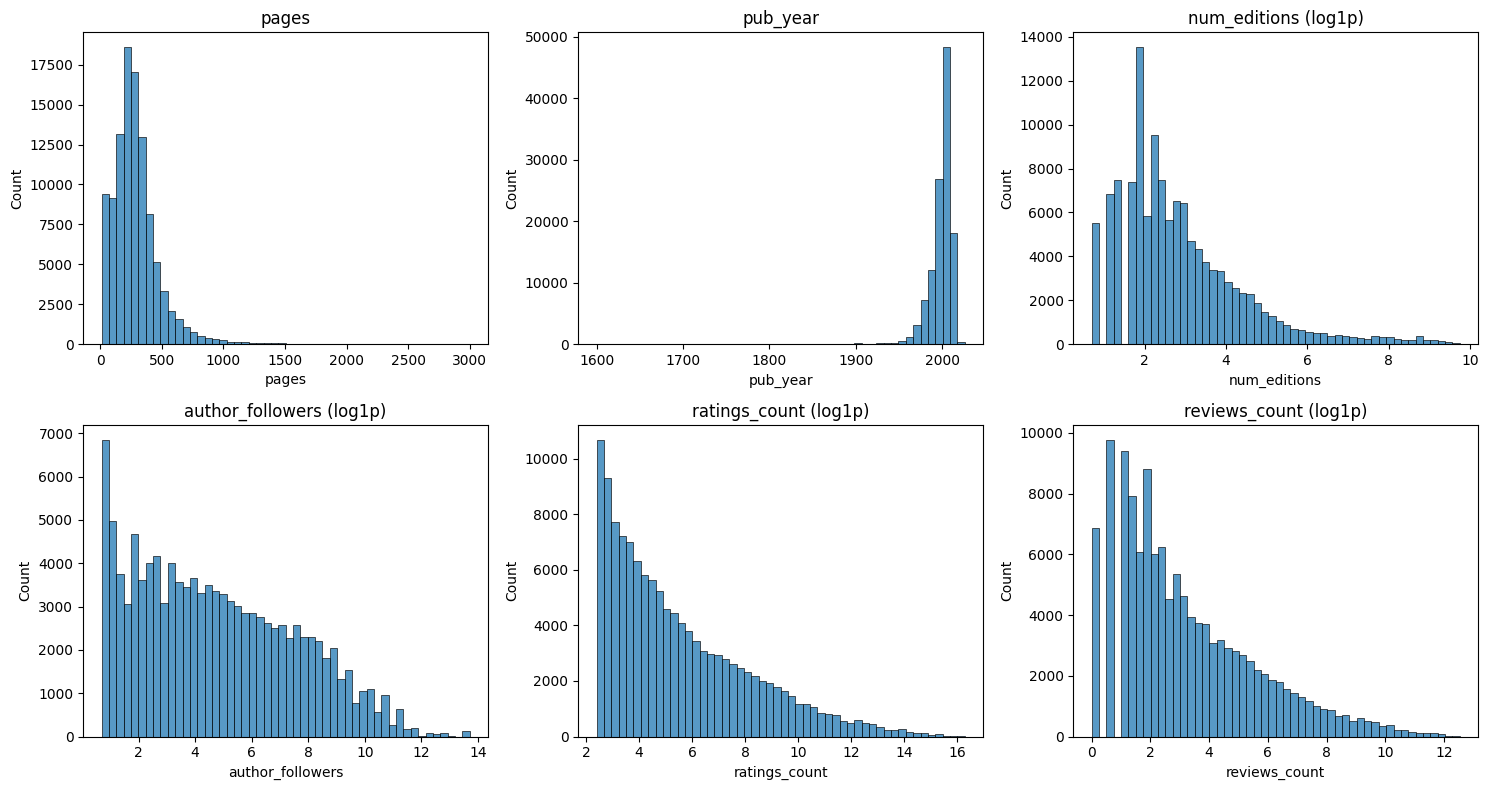

In [22]:
import numpy as np
print(np.__name__)

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
cols = {
    'pages': dfp['pages'],
    'pub_year': dfp['pub_year'],
    'num_editions (log1p)': np.log1p(dfp['num_editions']),
    'author_followers (log1p)': np.log1p(dfp['author_followers']),
    'ratings_count (log1p)': np.log1p(dfp['ratings_count']),
    'reviews_count (log1p)': np.log1p(dfp['reviews_count']),
}
for ax, (name, s) in zip(axes.ravel(), cols.items()):
    sns.histplot(s.dropna(), bins=50, ax=ax)
    ax.set_title(name)
plt.tight_layout()
plt.show()

***Spearman rank correlation was used because most features are skewed. The strongest association with average_rating was observed for ratings_count (ρ = 0.135), followed by author_followers (ρ = 0.115). The relationships were weak for pub_year (ρ = −0.036), num_editions (ρ = 0.067) and author_works (ρ = 0.071). All correlations stayed below 0.14 in absolute value.***

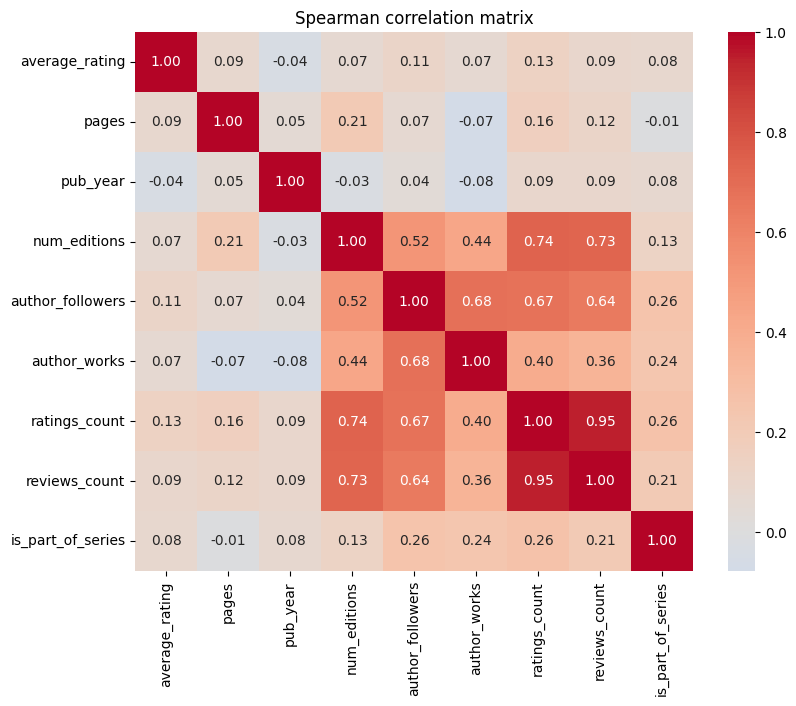

,average_rating
ratings_count,0.134796
author_followers,0.114852
reviews_count,0.090997
pages,0.085165
is_part_of_series,0.081401
author_works,0.071339
num_editions,0.067188
pub_year,-0.036456


In [23]:
num_cols = ['average_rating', 'pages', 'pub_year', 'num_editions', 'author_followers',
            'author_works', 'ratings_count', 'reviews_count', 'is_part_of_series']
corr = dfp[num_cols].corr(method='spearman')

plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Spearman correlation matrix')
plt.show()

corr['average_rating'].drop('average_rating').sort_values(ascending=False)

***Binning numeric features showed non-linear relationships with the rating (e.g.,page count, where very short books average 3.87, mid-length books about 3.81 and the longest books 3.99), which motivates tree-based models that can capture such patterns.***

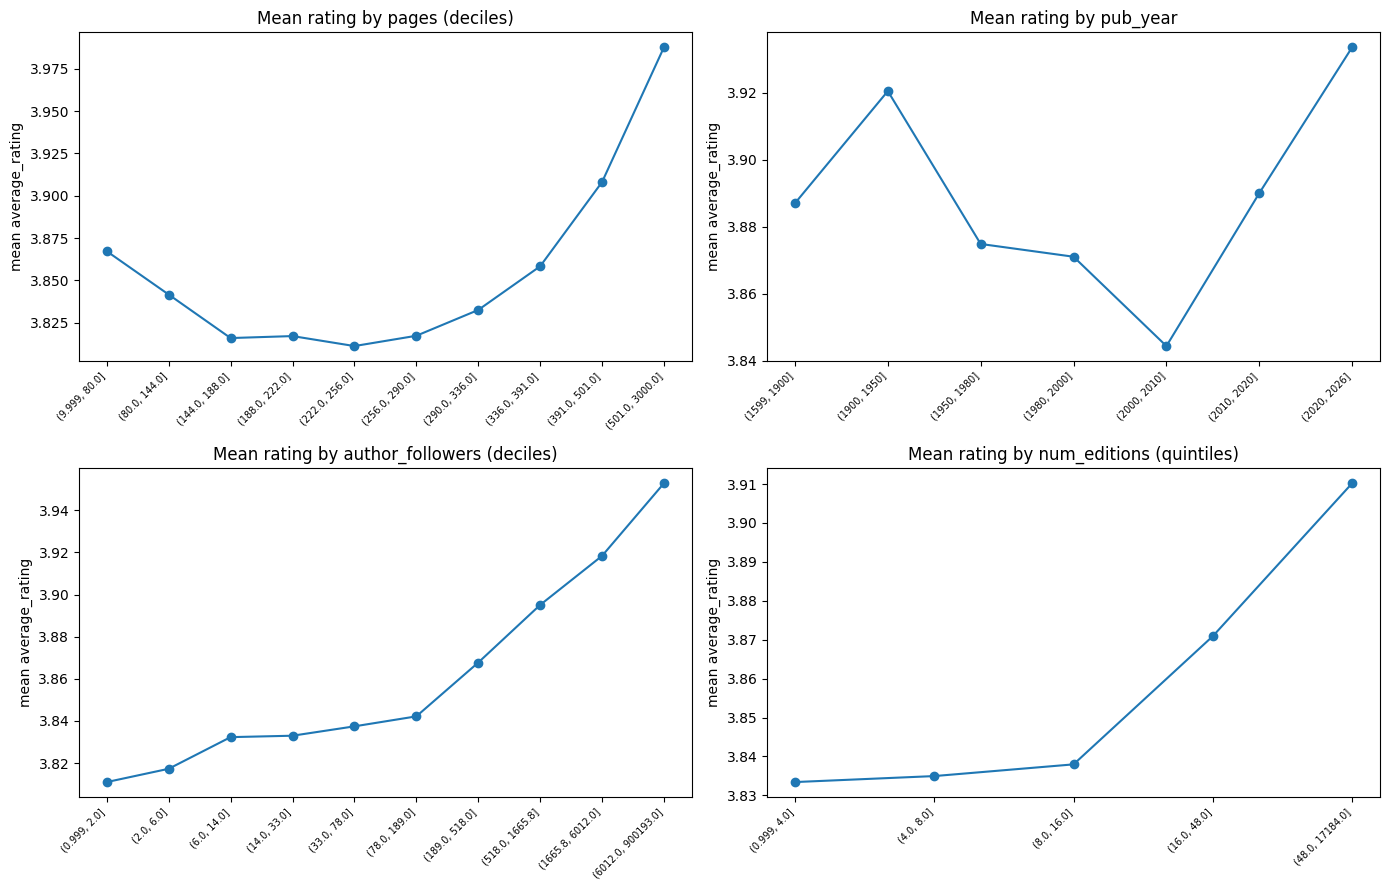

pages (deciles)
                 count   mean
bin                          
(9.999, 80.0]    10680  3.867
(80.0, 144.0]    10774  3.842
(144.0, 188.0]   10026  3.816
(188.0, 222.0]   10512  3.817
(222.0, 256.0]   12385  3.811
(256.0, 290.0]    8641  3.817
(290.0, 336.0]   11258  3.833
(336.0, 391.0]    9666  3.858
(391.0, 501.0]   10490  3.908
(501.0, 3000.0]  10458  3.988

pub_year
              count   mean
bin                       
(1599, 1900]    334  3.887
(1900, 1950]    630  3.920
(1950, 1980]   9054  3.875
(1980, 2000]  41722  3.871
(2000, 2010]  64054  3.844
(2010, 2020]   2543  3.890
(2020, 2026]    168  3.934

author_followers (deciles)
                    count   mean
bin                             
(0.999, 2.0]        11839  3.811
(2.0, 6.0]          11476  3.817
(6.0, 14.0]         10874  3.832
(14.0, 33.0]        11233  3.833
(33.0, 78.0]        11308  3.837
(78.0, 189.0]       11215  3.842
(189.0, 518.0]      11289  3.868
(518.0, 1665.8]     11311  3.895
(1665.8, 6012

In [24]:
def binned(col, q=None, bins=None):
    s = dfp[[col, 'average_rating']].dropna().copy()
    s['bin'] = pd.qcut(s[col], q=q, duplicates='drop') if q else pd.cut(s[col], bins=bins)
    return s.groupby('bin', observed=True)['average_rating'].agg(['count', 'mean'])

tables = {
    'pages (deciles)': binned('pages', q=10),
    'pub_year': binned('pub_year', bins=[1599, 1900, 1950, 1980, 2000, 2010, 2020, 2026]),
    'author_followers (deciles)': binned('author_followers', q=10),
    'num_editions (quintiles)': binned('num_editions', q=5),
}

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, (name, t) in zip(axes.ravel(), tables.items()):
    ax.plot(range(len(t)), t['mean'], marker='o')
    ax.set_xticks(range(len(t)))
    ax.set_xticklabels([str(i) for i in t.index], rotation=45, ha='right', fontsize=7)
    ax.set_title(f'Mean rating by {name}')
    ax.set_ylabel('mean average_rating')
plt.tight_layout()
plt.show()

for name, t in tables.items():
    print(name)
    print(t.round(3))
    print()

***Genre-level statistics were computed with a SQL JOIN between the normalized book_genres table and books_prepared. The highest-rated genres were Faith (4.26), Christianity (4.17) and Theology (4.15), and the lowest were Harlequin (3.55) and Erotica (3.66), indicating that genre carries predictive signal.***

In [25]:
fmt = con.execute("""
SELECT format, COUNT(*) AS n_books, ROUND(AVG(average_rating), 3) AS avg_rating
FROM books_prepared
GROUP BY format
HAVING COUNT(*) >= 300
ORDER BY n_books DESC
""").df()
print(fmt)

genres = con.execute("""
SELECT g.genre, COUNT(*) AS n_books, ROUND(AVG(b.average_rating), 3) AS avg_rating
FROM book_genres g
JOIN books_prepared b USING (book_id)
GROUP BY g.genre
HAVING COUNT(*) >= 1000
ORDER BY avg_rating DESC
""").df()
print(genres.head(10))
print(genres.tail(10))

                   format  n_books  avg_rating
0               Paperback    61243       3.854
1               Hardcover    34286       3.882
2          Kindle Edition     7642       3.815
3   Mass Market Paperback     6705       3.777
4         Library Binding     2426       3.865
5                Audio CD     2420       3.886
6          Audio Cassette     1969       3.917
7                 Unknown     1652       3.840
8                   ebook     1392       3.800
9         Unknown Binding      899       3.858
10                   Nook      627       3.757
11                             468       3.791
12              Audiobook      456       3.931
13                 MP3 CD      413       3.876
14             Board Book      300       3.873
               genre  n_books  avg_rating
0              Faith     1276       4.257
1       Christianity     2281       4.165
2           Theology     2435       4.149
3          Christian     3924       4.145
4       Spirituality     3694       4.

***The average rating differs between books with and without author follower data (3.83 vs 3.86), suggesting that missingness itself may be informative; therefore missing values were kept rather than dropped.***

In [26]:
for c in ['pages', 'pub_year', 'author_followers', 'description']:
    miss = dfp[c].isna()
    print(f"{c:18s} missing: {miss.sum():6d} | "
          f"mean rating (missing): {dfp.loc[miss, 'average_rating'].mean():.3f} | "
          f"(present): {dfp.loc[~miss, 'average_rating'].mean():.3f}")

pages              missing:  20680 | mean rating (missing): 3.866 | (present): 3.856
pub_year           missing:   7065 | mean rating (missing): 3.850 | (present): 3.858
author_followers   missing:  12388 | mean rating (missing): 3.828 | (present): 3.861
description        missing:   1742 | mean rating (missing): 3.838 | (present): 3.858


## 5. Feature engineering and train/test split

***Data was split 80/20 into training and test sets (random_state=42) before any feature statistics were computed, so all learned vocabularies come from training set only and no test informatiom leaks into the features***

In [27]:
import re, json, warnings
import numpy as np
import pandas as pd
from collections import Counter
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MultiLabelBinarizer

dfp = con.execute("SELECT * FROM books_prepared").df()

train_df, test_df = train_test_split(dfp, test_size=0.2, random_state=42)
train_df = train_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print(train_df.shape, test_df.shape)
print("mean rating train/test:", round(train_df['average_rating'].mean(), 3),
      round(test_df['average_rating'].mean(), 3))

(100456, 17) (25114, 17)
mean rating train/test: 3.856 3.862


***Categories were frozen from training set: formats with at least 200 books, and the 100 most frequent genres (covering 75.3% of all genre tags). Rarer categories were grouped as (Other).***

In [28]:
MIN_FMT, MIN_LANG, TOP_GENRES = 200, 400, 100

def clean_cat(s):
    return s.fillna('Unknown').replace('', 'Unknown')

fmt_counts  = clean_cat(train_df['format']).value_counts()
lang_counts = clean_cat(train_df['language']).value_counts()
genre_counts = Counter(g for gs in train_df['genres'] for g in gs)

vocab = {
    'formats':   fmt_counts[fmt_counts >= MIN_FMT].index.tolist(),
    'languages': lang_counts[lang_counts >= MIN_LANG].index.tolist(),
    'genres':    [g for g, _ in genre_counts.most_common(TOP_GENRES)],
    'publisher_counts': clean_cat(train_df['publisher']).value_counts().to_dict(),
}

covered = sum(genre_counts[g] for g in vocab['genres']) / sum(genre_counts.values())
print(len(vocab['formats']), "formats |", len(vocab['languages']), "languages |",
      len(vocab['genres']), "genres")
print(f"top-{TOP_GENRES} genres cover {covered:.1%} of all genre tags")
print(vocab['formats'])
print(vocab['languages'])

15 formats | 11 languages | 100 genres
top-100 genres cover 75.3% of all genre tags
['Paperback', 'Hardcover', 'Kindle Edition', 'Mass Market Paperback', 'Library Binding', 'Audio CD', 'Unknown', 'Audio Cassette', 'ebook', 'Unknown Binding', 'Nook', 'Audiobook', 'MP3 CD', 'Board Book', 'Pocket Book']
['English', 'Unknown', 'Spanish; Castilian', 'German', 'French', 'Italian', 'Indonesian', 'Japanese', 'Portuguese', 'Dutch; Flemish', 'Arabic']


***Count-type features were log-transformed. New features were derived from nested and text fields (number of genres, title and description length), missing-value indicators were added, categorical features were one-hot encoded, genres were multi-hot encoded, and publisher identity was summarized by its training-set frequency to avoid high-cardinality encoding.***

In [29]:
def build_features(df, vocab):
    X = pd.DataFrame(index=df.index)

    # numeric (log for count-type columns)
    X['pages'] = df['pages']
    X['pub_year'] = df['pub_year']
    X['log_num_editions'] = np.log1p(df['num_editions'])
    X['log_author_followers'] = np.log1p(df['author_followers'])
    X['log_author_works'] = np.log1p(df['author_works'])
    X['is_part_of_series'] = df['is_part_of_series'].astype(int)

    # derived
    X['n_genres'] = df['genres'].apply(len)
    X['title_words'] = df['title'].fillna('').str.split().str.len()
    X['desc_words'] = df['description'].fillna('').str.split().str.len()
    X['has_description'] = df['description'].notna().astype(int)

    # missing-value indicators
    X['pages_missing'] = df['pages'].isna().astype(int)
    X['year_missing'] = df['pub_year'].isna().astype(int)
    X['followers_missing'] = df['author_followers'].isna().astype(int)

    # publisher frequency (learned from training only)
    X['log_publisher_books'] = np.log1p(
        clean_cat(df['publisher']).map(vocab['publisher_counts']).fillna(0))

    # one-hot: format and language (rare -> Other)
    for col, key, prefix in [('format', 'formats', 'format'), ('language', 'languages', 'lang')]:
        s = clean_cat(df[col])
        s = s.where(s.isin(vocab[key]), 'Other')
        s = pd.Series(pd.Categorical(s, categories=vocab[key] + ['Other']), index=df.index)
        X = X.join(pd.get_dummies(s, prefix=prefix, dtype=int))

    # multi-hot: genres
    mlb = MultiLabelBinarizer(classes=vocab['genres'])
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')   # genres outside the top-100 are ignored on purpose
        G = mlb.fit_transform(df['genres'].apply(list))
    clean_names = [re.sub(r'[^0-9A-Za-z]+', '_', g) for g in vocab['genres']]
    gcols = [f"g{i:03d}_{c}" for i, c in enumerate(clean_names)]
    X = X.join(pd.DataFrame(G, columns=gcols, index=df.index))

# popularity features (kept separate for the leakage experiment)
    X['log_ratings_count'] = np.log1p(df['ratings_count'])
    X['log_reviews_count'] = np.log1p(df['reviews_count'])

    X.columns = [re.sub(r'[\[\]<>\s]+', '_', c) for c in X.columns]
    return X

***The final design matrix has 142 features (the two popularity features are held out of the main set). Remaining missing values (pages, publication year, author metrics) were left as NaN: tree-based models handle them natively, and the linear baseline uses training-set medians.***

In [30]:
X_train = build_features(train_df, vocab)
X_test  = build_features(test_df, vocab)
y_train = train_df['average_rating']
y_test  = test_df['average_rating']

assert list(X_train.columns) == list(X_test.columns)

POP_COLS = ['log_ratings_count', 'log_reviews_count']
FEATURE_COLS = [c for c in X_train.columns if c not in POP_COLS]

print(X_train.shape, X_test.shape)
print(len(FEATURE_COLS), "main features +", len(POP_COLS), "popularity features")

na = X_train[FEATURE_COLS].isna().sum()
print(na[na > 0])

out = '/content/drive/MyDrive/'
X_train.assign(average_rating=y_train.values, book_id=train_df['book_id'].values) \
       .to_parquet(out + 'features_train.parquet')
X_test.assign(average_rating=y_test.values, book_id=test_df['book_id'].values) \
      .to_parquet(out + 'features_test.parquet')
json.dump({'FEATURE_COLS': FEATURE_COLS, 'POP_COLS': POP_COLS},
          open(out + 'feature_lists.json', 'w'))
print("saved")

(100456, 144) (25114, 144)
142 main features + 2 popularity features
pages                   16499
pub_year                 5647
log_num_editions            1
log_author_followers     9946
log_author_works         1354
dtype: int64
saved


***As a sanity check, Spearman correlations with the rating on the training set were computed for the engineered features; the strongest were the genre flags Christian (ρ = 0.149) and Spirituality (ρ = 0.143), followed by Religion (0.122) and the number of genres per book (0.121).***

In [31]:
corr_new = X_train[FEATURE_COLS].corrwith(y_train, method='spearman')
top = corr_new.reindex(corr_new.abs().sort_values(ascending=False).index).head(15)
print(top.round(3))

g038_Christian          0.149
g041_Spirituality       0.143
g022_Religion           0.122
n_genres                0.121
g062_Christianity       0.120
log_author_followers    0.118
g060_Theology           0.117
g094_Faith              0.113
g001_Nonfiction         0.106
title_words             0.096
pages                   0.088
g033_Poetry             0.087
g017_Philosophy         0.085
g096_Harlequin         -0.083
is_part_of_series       0.083
dtype: float64


***The final design matrix has 144 columns: 142 main features and 2 popularity features held out for the leakage experiment. Remaining missing values (pages 16.4%, publication year 5.6%, author followers 9.9%) were left as NaN: tree-based models handle them natively, and the linear baseline uses training-set medians.***

***As a sanity check, Spearman correlations with the rating were computed on the training set. The strongest were the genre flags Christian (ρ = 0.149), Spirituality (0.143) and Religion (0.122), followed by the number of genres per book (0.121). No feature exceeded |ρ| = 0.15.***

## 6. Baseline models

Load the saved feature files (142 main features; the two popularity features are held out for the leakage experiment).

In [32]:
import json
import numpy as np
import pandas as pd

out = '/content/drive/MyDrive/'
tr = pd.read_parquet(out + 'features_train.parquet')
te = pd.read_parquet(out + 'features_test.parquet')
cols = json.load(open(out + 'feature_lists.json'))
FEATURE_COLS, POP_COLS = cols['FEATURE_COLS'], cols['POP_COLS']

X_train, y_train = tr[FEATURE_COLS], tr['average_rating']
X_test, y_test = te[FEATURE_COLS], te['average_rating']
print(X_train.shape, X_test.shape)

(100456, 142) (25114, 142)


Evaluation helper: MSE, RMSE, MAE and R² for any fitted model, plus the mean-predictor baseline.

In [33]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

def evaluate(name, model, X, y):
    pred = model.predict(X)
    mse = mean_squared_error(y, pred)
    return {'model': name, 'MSE': mse, 'RMSE': mse ** 0.5,
            'MAE': mean_absolute_error(y, pred), 'R2': r2_score(y, pred)}

dummy = DummyRegressor(strategy='mean').fit(X_train, y_train)
results = [evaluate('Mean predictor', dummy, X_test, y_test)]
pd.DataFrame(results).round(4)

,model,MSE,RMSE,MAE,R2
0,Mean predictor,0.1286,0.3586,0.2786,-0.0003


Linear Regression and Ridge baselines. Median imputation and standardization are fitted on the training set only (pipeline).

In [34]:
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge

lin = make_pipeline(SimpleImputer(strategy='median'), StandardScaler(), LinearRegression())
lin.fit(X_train, y_train)

ridge = make_pipeline(SimpleImputer(strategy='median'), StandardScaler(), Ridge(alpha=10))
ridge.fit(X_train, y_train)

results.append(evaluate('Linear Regression', lin, X_test, y_test))
results.append(evaluate('Ridge (alpha=10)', ridge, X_test, y_test))
pd.DataFrame(results).round(4)

,model,MSE,RMSE,MAE,R2
0,Mean predictor,0.1286,0.3586,0.2786,-0.0003
1,Linear Regression,0.1079,0.3285,0.2510,0.1604
2,Ridge (alpha=10),0.1079,0.3285,0.2510,0.1604


Train versus test comparison, to check for overfitting.

In [35]:
check = [evaluate('Linear (train)', lin, X_train, y_train),
         evaluate('Linear (test)', lin, X_test, y_test)]
pd.DataFrame(check).round(4)

,model,MSE,RMSE,MAE,R2
0,Linear (train),0.1082,0.3289,0.252,0.1660
1,Linear (test),0.1079,0.3285,0.251,0.1604


Linear model coefficients. Features are standardized, so coefficient magnitudes are comparable.

In [36]:
coef = pd.Series(lin[-1].coef_, index=X_train.columns)
print(coef.reindex(coef.abs().sort_values(ascending=False).index).head(15).round(3))

log_author_followers    0.080
n_genres                0.050
pages                   0.049
g000_Fiction           -0.042
is_part_of_series       0.034
log_author_works       -0.030
g096_Harlequin         -0.027
g038_Christian          0.026
log_publisher_books    -0.026
g033_Poetry             0.026
followers_missing      -0.026
g046_Art                0.025
title_words             0.024
g021_Science_Fiction   -0.022
g009_Mystery           -0.021
dtype: float64


Predicted versus actual ratings on the test set.

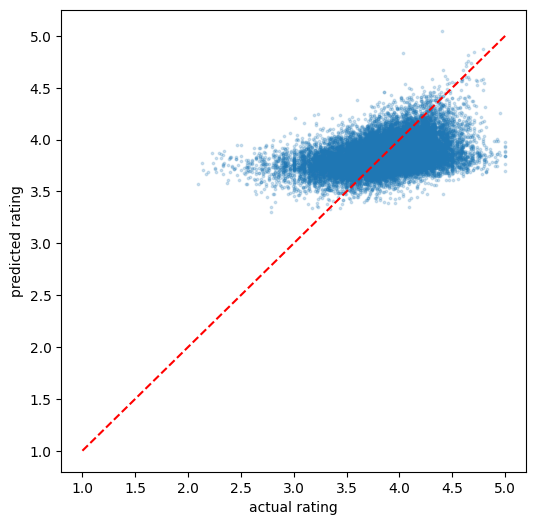

In [37]:
import matplotlib.pyplot as plt

pred = lin.predict(X_test)
plt.figure(figsize=(6, 6))
plt.scatter(y_test, pred, s=3, alpha=0.2)
plt.plot([1, 5], [1, 5], 'r--')
plt.xlabel('actual rating')
plt.ylabel('predicted rating')
plt.show()

## 7. XGBoost

Reading the saved features and creating the validation split (10% of the training set, random_state=42).

In [38]:
import json
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

# tr, te, FEATURE_COLS, X_test and y_test come from the baseline section above
X_train_full, y_train_full = tr[FEATURE_COLS], tr['average_rating']

X_tr, X_val, y_tr, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.1, random_state=42)
print(X_tr.shape, X_val.shape, X_test.shape)

(90410, 142) (10046, 142) (25114, 142)


XGBoost with early stopping on the validation split.

XGBoost builds boosted decision trees, each one correcting the errors of the previous ones. Early stopping halts training when the validation RMSE stops improving.

In [39]:
from xgboost import XGBRegressor

xgb = XGBRegressor(
    n_estimators=2000,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    tree_method='hist',
    eval_metric='rmse',
    early_stopping_rounds=50,
    random_state=42,
    n_jobs=-1,
)
xgb.fit(X_tr, y_tr, eval_set=[(X_tr, y_tr), (X_val, y_val)], verbose=100)
print('best iteration:', xgb.best_iteration)

[0]	validation_0-rmse:0.35819	validation_1-rmse:0.35975
[100]	validation_0-rmse:0.31570	validation_1-rmse:0.32126
[200]	validation_0-rmse:0.30604	validation_1-rmse:0.31540
[300]	validation_0-rmse:0.29961	validation_1-rmse:0.31268
[400]	validation_0-rmse:0.29465	validation_1-rmse:0.31079
[500]	validation_0-rmse:0.28965	validation_1-rmse:0.30960
[600]	validation_0-rmse:0.28530	validation_1-rmse:0.30878
[700]	validation_0-rmse:0.28090	validation_1-rmse:0.30825
[800]	validation_0-rmse:0.27672	validation_1-rmse:0.30758
[900]	validation_0-rmse:0.27282	validation_1-rmse:0.30714
[1000]	validation_0-rmse:0.26902	validation_1-rmse:0.30686
[1049]	validation_0-rmse:0.26709	validation_1-rmse:0.30689
best iteration: 999


Test-set evaluation of XGBoost, next to the mean-predictor and linear baselines.

In [40]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

def evaluate(name, model, X, y):
    pred = model.predict(X)
    mse = mean_squared_error(y, pred)
    return {'model': name, 'MSE': mse, 'RMSE': mse ** 0.5,
            'MAE': mean_absolute_error(y, pred), 'R2': r2_score(y, pred)}

res = pd.DataFrame([
    {'model': 'Mean predictor', 'MSE': 0.1286, 'RMSE': 0.3586, 'MAE': 0.2786, 'R2': -0.0003},
    {'model': 'Linear Regression', 'MSE': 0.1079, 'RMSE': 0.3285, 'MAE': 0.2510, 'R2': 0.1604},
    evaluate('XGBoost', xgb, X_test, y_test),
])
res.round(4)

,model,MSE,RMSE,MAE,R2
0,Mean predictor,0.1286,0.3586,0.2786,-0.0003
1,Linear Regression,0.1079,0.3285,0.2510,0.1604
2,XGBoost,0.0952,0.3086,0.2318,0.2593


Train, validation and test comparison for XGBoost.

In [41]:
check = pd.DataFrame([
    evaluate('XGB (train)', xgb, X_tr, y_tr),
    evaluate('XGB (validation)', xgb, X_val, y_val),
    evaluate('XGB (test)', xgb, X_test, y_test),
])
check.round(4)

,model,MSE,RMSE,MAE,R2
0,XGB (train),0.0724,0.2691,0.2021,0.4414
1,XGB (validation),0.0942,0.3069,0.2304,0.2783
2,XGB (test),0.0952,0.3086,0.2318,0.2593


Learning curve: training and validation RMSE per boosting round.

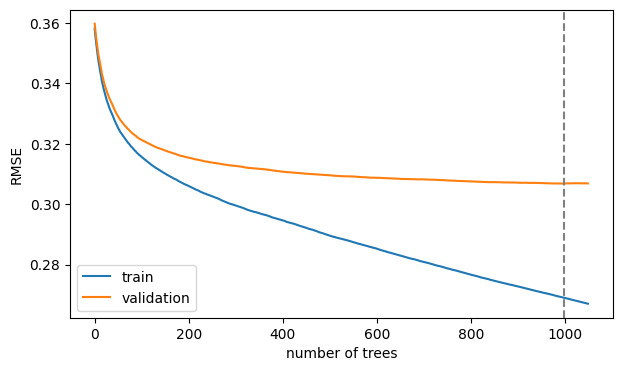

In [42]:
import matplotlib.pyplot as plt

hist = xgb.evals_result()
plt.figure(figsize=(7, 4))
plt.plot(hist['validation_0']['rmse'], label='train')
plt.plot(hist['validation_1']['rmse'], label='validation')
plt.axvline(xgb.best_iteration, color='gray', linestyle='--')
plt.xlabel('number of trees')
plt.ylabel('RMSE')
plt.legend()
plt.show()

Feature importance (gain).

In [43]:
imp = pd.Series(xgb.feature_importances_, index=X_tr.columns).sort_values(ascending=False)
print(imp.head(15).round(4))

g038_Christian       0.0712
g041_Spirituality    0.0558
g046_Art             0.0336
g096_Harlequin       0.0316
g033_Poetry          0.0269
g086_Nature          0.0224
g071_Manga           0.0188
g008_Childrens       0.0188
g001_Nonfiction      0.0177
g000_Fiction         0.0165
g006_Romance         0.0155
is_part_of_series    0.0154
g015_Contemporary    0.0150
g055_Chick_Lit       0.0148
g095_Westerns        0.0133
dtype: float32


In [44]:
print('best iteration:', xgb.best_iteration)
print()
print(res.round(4).to_string(index=False))
print()
print(check.round(4).to_string(index=False))
print()

hist = xgb.evals_result()
tr_curve = hist['validation_0']['rmse']
val_curve = hist['validation_1']['rmse']
n = len(val_curve)
print('iter  train_rmse  val_rmse')
for i in sorted(set([0, 50, 100, 200, 400, xgb.best_iteration, n - 1])):
    if i < n:
        print(i, round(tr_curve[i], 4), round(val_curve[i], 4))
print()

print(imp.head(15).round(4).to_string())

best iteration: 999

            model    MSE   RMSE    MAE      R2
   Mean predictor 0.1286 0.3586 0.2786 -0.0003
Linear Regression 0.1079 0.3285 0.2510  0.1604
          XGBoost 0.0952 0.3086 0.2318  0.2593

           model    MSE   RMSE    MAE     R2
     XGB (train) 0.0724 0.2691 0.2021 0.4414
XGB (validation) 0.0942 0.3069 0.2304 0.2783
      XGB (test) 0.0952 0.3086 0.2318 0.2593

iter  train_rmse  val_rmse
0 0.3582 0.3597
50 0.3252 0.329
100 0.3157 0.3213
200 0.306 0.3154
400 0.2946 0.3108
999 0.2691 0.3069
1049 0.2671 0.3069

g038_Christian       0.0712
g041_Spirituality    0.0558
g046_Art             0.0336
g096_Harlequin       0.0316
g033_Poetry          0.0269
g086_Nature          0.0224
g071_Manga           0.0188
g008_Childrens       0.0188
g001_Nonfiction      0.0177
g000_Fiction         0.0165
g006_Romance         0.0155
is_part_of_series    0.0154
g015_Contemporary    0.0150
g055_Chick_Lit       0.0148
g095_Westerns        0.0133


## 8. Tuning and Random Forest

Hyperparameter tuning: random search over 8 configurations on a 40,000-row subsample, compared on the validation split only.

Random Forest as a second tree-based model. Median imputation is fitted on the training data only.

In [45]:
import random, time
import numpy as np
from xgboost import XGBRegressor

print('Training rows:', len(X_tr))

rs = np.random.RandomState(42)
idx = rs.choice(len(X_tr), size=40_000, replace=False)
X_s, y_s = X_tr.iloc[idx], y_tr.iloc[idx]

random.seed(42)
space = {
    'max_depth': [3, 4, 5, 6],
    'min_child_weight': [1, 5, 10, 20],
    'reg_lambda': [1, 5, 10, 30],
    'reg_alpha': [0, 0.1, 1],
    'subsample': [0.6, 0.8, 1.0],
    'colsample_bytree': [0.4, 0.6, 0.8],
}
results = []
for i in range(8):
    p = {k: random.choice(v) for k, v in space.items()}
    t0 = time.time()
    m = XGBRegressor(n_estimators=400, learning_rate=0.15, tree_method='hist',
                     max_bin=64, eval_metric='rmse', early_stopping_rounds=20,
                     random_state=42, n_jobs=-1, **p)
    m.fit(X_s, y_s, eval_set=[(X_val, y_val)], verbose=False)
    results.append((m.best_score, m.best_iteration, p))
    print(f'{i+1}/8  val RMSE={m.best_score:.4f}  iter={m.best_iteration}  {round(time.time()-t0)}s  {p}')

results.sort(key=lambda r: r[0])
best_rmse, best_iter, best_params = results[0]
print('\nBest:', round(best_rmse, 4), best_iter, best_params)

Training rows: 90410
1/8  val RMSE=0.3175  iter=396  30s  {'max_depth': 3, 'min_child_weight': 1, 'reg_lambda': 10, 'reg_alpha': 0, 'subsample': 0.6, 'colsample_bytree': 0.4}
2/8  val RMSE=0.3182  iter=397  30s  {'max_depth': 3, 'min_child_weight': 1, 'reg_lambda': 30, 'reg_alpha': 0, 'subsample': 0.6, 'colsample_bytree': 0.4}
3/8  val RMSE=0.3156  iter=305  23s  {'max_depth': 4, 'min_child_weight': 5, 'reg_lambda': 1, 'reg_alpha': 1, 'subsample': 0.6, 'colsample_bytree': 0.8}
4/8  val RMSE=0.3137  iter=293  27s  {'max_depth': 6, 'min_child_weight': 5, 'reg_lambda': 30, 'reg_alpha': 1, 'subsample': 0.8, 'colsample_bytree': 0.4}
5/8  val RMSE=0.3160  iter=317  27s  {'max_depth': 4, 'min_child_weight': 20, 'reg_lambda': 10, 'reg_alpha': 0.1, 'subsample': 0.6, 'colsample_bytree': 0.4}
6/8  val RMSE=0.3149  iter=249  20s  {'max_depth': 5, 'min_child_weight': 1, 'reg_lambda': 1, 'reg_alpha': 0.1, 'subsample': 0.6, 'colsample_bytree': 0.6}
7/8  val RMSE=0.3148  iter=244  23s  {'max_depth': 5

In [46]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error
import time

t0 = time.time()
rf = make_pipeline(
    SimpleImputer(strategy='median'),
    RandomForestRegressor(n_estimators=100, min_samples_leaf=10, max_features=0.4,
                          max_samples=0.4, n_jobs=-1, random_state=42))
rf.fit(X_tr, y_tr)
rf_val_rmse = mean_squared_error(y_val, rf.predict(X_val)) ** 0.5
print('RF val RMSE:', round(rf_val_rmse, 4), '|', round(time.time()-t0), 's')
print('XGB val RMSE (subsample search):', round(best_rmse, 4))

RF val RMSE: 0.3173 | 40 s
XGB val RMSE (subsample search): 0.3137


Refit the best XGBoost configuration on the full training split, compare it with the Random Forest on the validation split, and evaluate the winner once on the test set.

In [47]:
import json

xgb_final = XGBRegressor(n_estimators=2000, learning_rate=0.05, tree_method='hist',
                         eval_metric='rmse', early_stopping_rounds=50,
                         random_state=42, n_jobs=-1, **best_params)
xgb_final.fit(X_tr, y_tr, eval_set=[(X_val, y_val)], verbose=False)
xgb_val_rmse = mean_squared_error(y_val, xgb_final.predict(X_val)) ** 0.5
print('XGB tuned (full training split) val RMSE:', round(xgb_val_rmse, 4), '| iter:', xgb_final.best_iteration)
print('RF val RMSE:', round(rf_val_rmse, 4))

if xgb_val_rmse <= rf_val_rmse:
    winner_name, winner = 'XGBoost (tuned)', xgb_final
else:
    winner_name, winner = 'Random Forest', rf
print('Winner:', winner_name)

for split, X, y in [('train', X_tr, y_tr), ('val', X_val, y_val), ('test', X_test, y_test)]:
    print(evaluate(f'{winner_name} - {split}', winner, X, y))

with open('best_params.json', 'w') as f:
    json.dump({'winner': winner_name, 'params': best_params}, f)

XGB tuned (full training split) val RMSE: 0.307 | iter: 1677
RF val RMSE: 0.3173
Winner: XGBoost (tuned)
{'model': 'XGBoost (tuned) - train', 'MSE': 0.07547655327667492, 'RMSE': 0.2747299642861603, 'MAE': 0.20585623105402187, 'R2': 0.41754437445196657}
{'model': 'XGBoost (tuned) - val', 'MSE': 0.09427661264184724, 'RMSE': 0.30704496843597234, 'MAE': 0.23060652115989105, 'R2': 0.2774305826783202}
{'model': 'XGBoost (tuned) - test', 'MSE': 0.095072255711737, 'RMSE': 0.3083378921114578, 'MAE': 0.2315020728675178, 'R2': 0.26038198229990495}


## 9. Model analysis and data leakage

Permutation importance on an 8,000-row sample of the test set (increase in RMSE after shuffling each feature).

In [48]:
from sklearn.inspection import permutation_importance
import pandas as pd

rs = np.random.RandomState(42)
idx = rs.choice(len(X_test), size=8000, replace=False)
Xp, yp = X_test.iloc[idx], y_test.iloc[idx]

t0 = time.time()
pi = permutation_importance(xgb_final, Xp, yp, scoring='neg_root_mean_squared_error',
                            n_repeats=3, random_state=42, n_jobs=1)
imp = pd.Series(pi.importances_mean, index=X_test.columns).sort_values(ascending=False)
print(round(time.time()-t0), 's')
print(imp.head(15).round(5).to_string())

225 s
log_author_followers    0.02264
n_genres                0.01597
pages                   0.01230
log_num_editions        0.00680
g000_Fiction            0.00660
is_part_of_series       0.00647
log_author_works        0.00586
log_publisher_books     0.00397
pub_year                0.00380
title_words             0.00338
g033_Poetry             0.00301
g038_Christian          0.00246
lang_English            0.00238
g006_Romance            0.00234
g041_Spirituality       0.00211


Error analysis: residuals by true rating bin and by page-count quintile.

In [49]:
pred = xgb_final.predict(X_test)
res = pd.DataFrame({'y': y_test.values, 'pred': pred})
res['err'] = res['pred'] - res['y']
res['abs_err'] = res['err'].abs()

res['rating_bin'] = pd.cut(res['y'], [0, 3.0, 3.5, 4.0, 4.5, 5.01])
print(res.groupby('rating_bin', observed=True).agg(
    n=('y','size'), mean_err=('err','mean'), MAE=('abs_err','mean')).round(3).to_string())

res['pages_bin'] = pd.qcut(X_test['pages'].values, 5, duplicates='drop')
print()
print(res.groupby('pages_bin', observed=True).agg(
    n=('y','size'), MAE=('abs_err','mean')).round(3).to_string())

print('\nTop 0.5% absolute error cutoff:', round(res['abs_err'].quantile(0.995), 3))

                 n  mean_err    MAE
rating_bin                         
(0.0, 3.0]     489     0.852  0.852
(3.0, 3.5]    3302     0.376  0.381
(3.5, 4.0]   12573     0.041  0.140
(4.0, 4.5]    8139    -0.235  0.248
(4.5, 5.01]    611    -0.601  0.603

                    n    MAE
pages_bin                   
(9.999, 144.0]   4279  0.251
(144.0, 220.0]   4131  0.246
(220.0, 288.0]   4208  0.235
(288.0, 385.0]   4138  0.223
(385.0, 3000.0]  4177  0.211

Top 0.5% absolute error cutoff: 1.05


Data leakage experiment: add log_ratings_count and log_reviews_count, which are only known after a book has been rated.

In [50]:
import json
tr = pd.read_parquet('/content/drive/MyDrive/features_train.parquet')
te = pd.read_parquet('/content/drive/MyDrive/features_test.parquet')
fl = json.load(open('/content/drive/MyDrive/feature_lists.json'))
FEATURE_COLS, POP_COLS = fl['FEATURE_COLS'], fl['POP_COLS']

cols2 = FEATURE_COLS + POP_COLS
Xa, ya = tr[cols2], tr['average_rating']
Xa_tr, Xa_val, ya_tr, ya_val = train_test_split(Xa, ya, test_size=0.1, random_state=42)

t0 = time.time()
xgb_leak = XGBRegressor(n_estimators=2000, learning_rate=0.05, tree_method='hist',
                        eval_metric='rmse', early_stopping_rounds=50,
                        random_state=42, n_jobs=-1, **best_params)
xgb_leak.fit(Xa_tr, ya_tr, eval_set=[(Xa_val, ya_val)], verbose=False)
print(round(time.time()-t0), 's | iter:', xgb_leak.best_iteration)

for name, X, y in [('Without popularity features', X_test, y_test),
                   ('With popularity features', te[cols2], te['average_rating'])]:
    m = xgb_final if 'Without' in name else xgb_leak
    print(evaluate(name, m, X, y))

163 s | iter: 1570
{'model': 'Without popularity features', 'MSE': 0.095072255711737, 'RMSE': 0.3083378921114578, 'MAE': 0.2315020728675178, 'R2': 0.26038198229990495}
{'model': 'With popularity features', 'MSE': 0.09128363891671111, 'RMSE': 0.3021318237404182, 'MAE': 0.2255846331398075, 'R2': 0.28985566232132476}


## 10. Applying chapters 18 to 20 in DuckDB

Physical design inspection: columns, data types, row counts and file size.

In [51]:
for t in ['books_prepared', 'book_genres']:
    print(t)
    print(con.execute(f"DESCRIBE {t}").fetchdf()[['column_name', 'column_type', 'null']].to_string())
    print()

print(con.execute("SELECT table_name, estimated_size, column_count FROM duckdb_tables()").fetchdf().to_string())
print()
print(con.execute("SELECT * FROM pragma_database_size()").fetchdf().T.to_string())

books_prepared
          column_name column_type null
0             book_id     VARCHAR  YES
1               title     VARCHAR  YES
2        first_author     VARCHAR  YES
3         description     VARCHAR  YES
4              format     VARCHAR  YES
5            language     VARCHAR  YES
6           publisher     VARCHAR  YES
7               pages      BIGINT  YES
8            pub_year      BIGINT  YES
9        num_editions      BIGINT  YES
10  is_part_of_series     BOOLEAN  YES
11   author_followers      BIGINT  YES
12       author_works      BIGINT  YES
13             genres   VARCHAR[]  YES
14      ratings_count      BIGINT  YES
15      reviews_count      BIGINT  YES
16     average_rating      DOUBLE  YES

book_genres
  column_name column_type null
0     book_id     VARCHAR  YES
1       genre     VARCHAR  YES

          table_name  estimated_size  column_count
0              books          315000            24
1        books_clean          125570            17
2        books_final   

Checks before enforcing constraints: unique ids, no nulls, valid ranges.

In [52]:
print(con.execute("""
SELECT COUNT(*) AS n,
       COUNT(DISTINCT book_id) AS uniq_ids,
       COUNT(*) FILTER (WHERE book_id IS NULL) AS null_ids,
       COUNT(*) FILTER (WHERE average_rating IS NULL) AS null_rating,
       COUNT(*) FILTER (WHERE average_rating NOT BETWEEN 0 AND 5) AS bad_rating,
       MIN(pages) AS min_pages, MAX(pages) AS max_pages,
       MIN(pub_year) AS min_year, MAX(pub_year) AS max_year,
       MIN(num_editions) AS min_ed
FROM books_prepared""").fetchdf().T.to_string())

                  0
n            125570
uniq_ids     125570
null_ids          0
null_rating       0
bad_rating        0
min_pages        10
max_pages      3000
min_year       1600
max_year       2026
min_ed            1


Final tables with explicit constraints (PRIMARY KEY, NOT NULL, CHECK, FOREIGN KEY). An invalid insert is rejected by the database.

Drop dependent objects first so this section can be re-run.

In [53]:
# Drop dependent objects first (views, child table, index) so this section can be re-run
con.execute("DROP VIEW IF EXISTS v_genre_stats")
con.execute("DROP VIEW IF EXISTS v_books_public")
con.execute("DROP TABLE IF EXISTS book_genres_final")
con.execute("DROP INDEX IF EXISTS idx_publisher")
con.execute("DROP TABLE IF EXISTS books_final")

In [54]:
con.execute("""
CREATE OR REPLACE TABLE books_final (
  book_id VARCHAR PRIMARY KEY,
  title VARCHAR,
  first_author VARCHAR,
  format VARCHAR,
  language VARCHAR,
  publisher VARCHAR,
  pages BIGINT CHECK (pages IS NULL OR pages BETWEEN 1 AND 10000),
  pub_year BIGINT CHECK (pub_year IS NULL OR pub_year BETWEEN 1000 AND 2026),
  num_editions BIGINT CHECK (num_editions IS NULL OR num_editions >= 1),
  is_part_of_series BOOLEAN,
  author_followers BIGINT CHECK (author_followers IS NULL OR author_followers >= 0),
  author_works BIGINT CHECK (author_works IS NULL OR author_works >= 0),
  ratings_count BIGINT CHECK (ratings_count IS NULL OR ratings_count >= 0),
  reviews_count BIGINT CHECK (reviews_count IS NULL OR reviews_count >= 0),
  average_rating DOUBLE NOT NULL CHECK (average_rating BETWEEN 0 AND 5)
)""")
con.execute("""
INSERT INTO books_final
SELECT book_id, title, first_author, format, language, publisher, pages, pub_year,
       num_editions, is_part_of_series, author_followers, author_works,
       ratings_count, reviews_count, average_rating
FROM books_prepared""")
print(con.execute("SELECT COUNT(*) FROM books_final").fetchone())

con.execute("""
CREATE OR REPLACE TABLE book_genres_final (
  book_id VARCHAR NOT NULL REFERENCES books_final(book_id),
  genre VARCHAR NOT NULL
)""")
con.execute("INSERT INTO book_genres_final SELECT book_id, genre FROM book_genres")
print(con.execute("SELECT COUNT(*) FROM book_genres_final").fetchone())

try:
    con.execute("INSERT INTO books_final (book_id, average_rating) VALUES ('test', 7.5)")
except Exception as e:
    print(type(e).__name__, str(e)[:160])

(125570,)
(661572,)
ConstraintException Constraint Error: CHECK constraint failed on table books_final with expression CHECK((average_rating BETWEEN 0 AND 5))


Index experiment: average lookup time over 30 runs before and after CREATE INDEX on publisher, with the query plan.

In [55]:
import time
pub = con.execute("""SELECT publisher FROM books_final WHERE publisher <> 'Unknown'
                     GROUP BY publisher HAVING COUNT(*) BETWEEN 5 AND 20 LIMIT 1""").fetchone()[0]
q = "SELECT COUNT(*), AVG(average_rating) FROM books_final WHERE publisher = ?"

def avg_ms(n=30):
    t0 = time.perf_counter()
    for _ in range(n):
        con.execute(q, [pub]).fetchall()
    return (time.perf_counter() - t0) / n * 1000

before = avg_ms()
con.execute("CREATE INDEX idx_publisher ON books_final(publisher)")
after = avg_ms()
print(pub, '| before:', round(before, 2), 'ms | after:', round(after, 2), 'ms')
print(con.execute("EXPLAIN " + q.replace('?', "'" + pub.replace("'", "''") + "'")).fetchall()[0][1])

Recorded Books, Inc. | before: 2.94 ms | after: 0.82 ms
┌───────────────────────────┐
│    UNGROUPED_AGGREGATE    │
│    ────────────────────   │
│        Aggregates:        │
│        count_star()       │
│          avg(#0)          │
└─────────────┬─────────────┘
┌─────────────┴─────────────┐
│         PROJECTION        │
│    ────────────────────   │
│       average_rating      │
│                           │
│          ~11 Rows         │
└─────────────┬─────────────┘
┌─────────────┴─────────────┐
│         SEQ_SCAN          │
│    ────────────────────   │
│     Table: books_final    │
│   Type: Sequential Scan   │
│                           │
│        Projections:       │
│       average_rating      │
│                           │
│          Filters:         │
│ publisher='Recorded Books,│
│            Inc.'          │
│                           │
│          ~11 Rows         │
└───────────────────────────┘



Views: a reusable genre statistics query and a restricted-column public view, followed by a table size estimate.

In [56]:
con.execute("""
CREATE OR REPLACE VIEW v_genre_stats AS
SELECT g.genre, COUNT(*) AS n_books, ROUND(AVG(b.average_rating), 3) AS avg_rating
FROM book_genres_final g JOIN books_final b USING (book_id)
GROUP BY g.genre HAVING COUNT(*) >= 100""")

con.execute("""
CREATE OR REPLACE VIEW v_books_public AS
SELECT book_id, format, language, pages, pub_year, is_part_of_series, average_rating
FROM books_final""")

print(con.execute("SELECT * FROM v_genre_stats ORDER BY avg_rating DESC LIMIT 5").fetchdf().to_string())
print(con.execute("SELECT * FROM v_genre_stats ORDER BY avg_rating ASC LIMIT 5").fetchdf().to_string())
print(con.execute("SELECT COUNT(*) FROM v_books_public").fetchone())

n, t, a, p, f, l, i = con.execute("""
SELECT COUNT(*), AVG(length(title)), AVG(length(first_author)), AVG(length(publisher)),
       AVG(length(format)), AVG(length(language)), AVG(length(book_id)) FROM books_final""").fetchone()
row_bytes = 8 * 8 + 1 + t + a + p + f + l + i
print(n, 'rows | approx. row size:', round(row_bytes), 'bytes | total:', round(n * row_bytes / 1024**2, 1), 'MiB (uncompressed)')

          genre  n_books  avg_rating
0    Devotional      222       4.336
1        Prayer      189       4.316
2         Faith     1276       4.257
3  Comic Strips      101       4.255
4      Catholic      472       4.241
                genre  n_books  avg_rating
0  Harlequin Presents      423       3.361
1   Harlequin Romance      341       3.441
2    Dutch Literature      118       3.518
3           Harlequin     1237       3.548
4                 Hqn      174       3.550
(125570,)
125570 rows | approx. row size: 152 bytes | total: 18.2 MiB (uncompressed)


Backups as Parquet exports, plus a CHECKPOINT to flush the write-ahead log.

In [57]:
con.execute("COPY books_final TO '/content/drive/MyDrive/books_final_backup.parquet' (FORMAT PARQUET)")
con.execute("COPY book_genres_final TO '/content/drive/MyDrive/book_genres_final_backup.parquet' (FORMAT PARQUET)")
con.execute("CHECKPOINT")
print(con.execute("SELECT view_name FROM duckdb_views() WHERE NOT internal").fetchdf().to_string())
print(con.execute("SELECT constraint_type, COUNT(*) FROM duckdb_constraints() GROUP BY 1").fetchdf().to_string())
print(con.execute("SELECT * FROM pragma_database_size()").fetchdf().T.loc[['database_size','wal_size']].to_string())

        view_name
0  v_books_public
1   v_genre_stats
  constraint_type  count_star()
0        NOT NULL             4
1     FOREIGN KEY             1
2     PRIMARY KEY             1
3           CHECK             8
                       0
database_size  810.7 MiB
wal_size         0 bytes


Control experiment for the index: measure again with the index dropped and re-created.

In [58]:
t_warm = avg_ms()
con.execute("DROP INDEX idx_publisher")
t_no_index = avg_ms()
con.execute("CREATE INDEX idx_publisher ON books_final(publisher)")
t_index = avg_ms()
print('no index (warm):', round(t_no_index, 2), 'ms | with index:', round(t_index, 2), 'ms | warm-up check:', round(t_warm, 2), 'ms')

no index (warm): 3.1 ms | with index: 0.84 ms | warm-up check: 1.06 ms


In [59]:
print(con.execute("""
SELECT g.genre, COUNT(*) AS n_books, ROUND(AVG(b.average_rating), 3) AS avg_rating
FROM book_genres g JOIN books_prepared b USING (book_id)
GROUP BY g.genre ORDER BY n_books DESC LIMIT 10""").fetchdf().to_string())

                genre  n_books  avg_rating
0             Fiction    45122       3.842
1          Nonfiction    34019       3.922
2            Classics    17406       3.920
3             History    16136       3.922
4           Audiobook    15174       3.913
5             Fantasy    13389       3.902
6             Romance    13170       3.811
7  Historical Fiction    12416       3.877
8           Childrens    12328       3.924
9             Mystery    11966       3.824
